In [1]:
from pathlib import Path 

import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
from IPython.display import display 
from sklearn.ensemble import RandomForestClassifier 
from sklearn.feature_selection import mutual_info_classif 
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, confusion_matrix, f1_score, precision_recall_fscore_support 
from sklearn.model_selection import train_test_split 
from sklearn.tree import DecisionTreeClassifier, export_text 

ROOT = Path.cwd().parent 
DATA = ROOT / "all_datasets" 
RESULTS = ROOT / "results" / "lab05" 
RESULTS.mkdir(parents=True, exist_ok=True)

In [2]:
sensors = [f"US{i:02d}" for i in range(24)] 
df = pd.read_csv(DATA / "lab05-sensor_readings_24.csv", header=None, names=sensors + ["action"]) 
X = df[sensors] 
y = df.action 

print("Shape:", df.shape) 
display(y.value_counts().rename("count").to_frame().assign(share=lambda t: (t["count"] / len(df)).round(3)))

display(X.describe().T[["mean", "std", "min", "max"]].round(2).head(6)) 

train_idx, test_idx = train_test_split(df.index, test_size=0.30, random_state=42, stratify=y)
split = pd.Series("train", index=df.index, name="split")
split[test_idx] = "test"   
split.rename_axis("row_id").to_csv(RESULTS / "split.csv") 
print({"train": len(train_idx), "test": len(test_idx)})

Shape: (5456, 25)


,count,share
action,,
Move-Forward,2205,0.404
Sharp-Right-Turn,2097,0.384
Slight-Right-Turn,826,0.151
Slight-Left-Turn,328,0.060


,mean,std,min,max
US00,1.47,0.80,0.40,5.00
US01,2.33,1.41,0.44,5.03
US02,2.49,1.25,0.47,5.03
US03,2.80,1.31,0.83,5.02
US04,2.96,1.34,1.12,5.00
US05,2.89,1.28,1.11,5.00


{'train': 3819, 'test': 1637}


In [4]:
mi = mutual_info_classif(X.loc[train_idx], y[train_idx], random_state=42) 
feature_table = pd.DataFrame({"sensor": sensors, "mutual_information": mi}).sort_values("mutual_information", ascending=False) 
feature_table.to_csv(RESULTS / "feature_scores.csv", index=False)
selected = feature_table.sensor.head(4).tolist() 
print("Selected sensors:", selected) 
display(feature_table.head(8).round(3))

Selected sensors: ['US14', 'US17', 'US18', 'US13']


,sensor,mutual_information
14,US14,0.596
17,US17,0.508
18,US18,0.452
13,US13,0.417
19,US19,0.414
22,US22,0.386
5,US05,0.376
12,US12,0.375


In [8]:
subtrain_idx, val_idx = train_test_split(train_idx, test_size=0.20, random_state=42, stratify=y[train_idx]) 

depth_results = [] 
for depth in [2, 3, 4, 5, 6]: 
    candidate = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=20, class_weight="balanced", random_state=42) 
    candidate.fit(X.loc[subtrain_idx, selected], y[subtrain_idx]) 
    score = f1_score(y[val_idx], candidate.predict(X.loc[val_idx, selected]), average="macro")
    depth_results.append({"max_depth": depth, "validation_macro_f1": score}) 
depth_table = pd.DataFrame(depth_results) 
display(depth_table.round(3)) 

best_depth = int(depth_table.loc[depth_table.validation_macro_f1.idxmax(), "max_depth"]) 
rule_model = DecisionTreeClassifier(max_depth=best_depth, min_samples_leaf=20, class_weight="balanced", random_state=42) 
rule_model.fit(X.loc[train_idx, selected], y[train_idx]) 

rules = export_text(rule_model, feature_names=selected) 
(RESULTS / "rule_controller.txt").write_text(rules) 
print("Selected depth:", best_depth, "| leaves:", rule_model.get_n_leaves()) 
print(rules) 

,max_depth,validation_macro_f1
0,2,0.463
1,3,0.826
2,4,0.872
3,5,0.887
4,6,0.883


Selected depth: 5 | leaves: 14
|--- US14 <= 0.90
|   |--- class: Sharp-Right-Turn
|--- US14 >  0.90
|   |--- US18 <= 1.00
|   |   |--- US18 <= 0.50
|   |   |   |--- US13 <= 1.20
|   |   |   |   |--- class: Sharp-Right-Turn
|   |   |   |--- US13 >  1.20
|   |   |   |   |--- US18 <= 0.50
|   |   |   |   |   |--- class: Slight-Right-Turn
|   |   |   |   |--- US18 >  0.50
|   |   |   |   |   |--- class: Slight-Right-Turn
|   |   |--- US18 >  0.50
|   |   |   |--- US13 <= 0.90
|   |   |   |   |--- class: Sharp-Right-Turn
|   |   |   |--- US13 >  0.90
|   |   |   |   |--- US17 <= 0.49
|   |   |   |   |   |--- class: Slight-Right-Turn
|   |   |   |   |--- US17 >  0.49
|   |   |   |   |   |--- class: Move-Forward
|   |--- US18 >  1.00
|   |   |--- US17 <= 0.90
|   |   |   |--- US17 <= 0.79
|   |   |   |   |--- US13 <= 1.41
|   |   |   |   |   |--- class: Move-Forward
|   |   |   |   |--- US13 >  1.41
|   |   |   |   |   |--- class: Move-Forward
|   |   |   |--- US17 >  0.79
|   |   |   |   |--

In [9]:
reference = RandomForestClassifier( 
    n_estimators=200, min_samples_leaf=2, class_weight="balanced_subsample", random_state=42, n_jobs=-1 
).fit(X.loc[train_idx], y[train_idx]) 
print("Random forest trained on", reference.n_features_in_, "sensors with", reference.n_estimators, "trees")

Random forest trained on 24 sensors with 200 trees


,model,accuracy,macro_precision,macro_recall,macro_f1
0,Interpretable rule tree,0.923,0.879,0.921,0.895
1,Random-forest reference,0.995,0.993,0.992,0.992


,precision,recall,f1
Move-Forward,0.907,0.943,0.924
Sharp-Right-Turn,1.000,0.913,0.954
Slight-Left-Turn,0.702,0.939,0.803
Slight-Right-Turn,0.906,0.891,0.898


Hardest action for the rule controller (lowest recall): Slight-Right-Turn


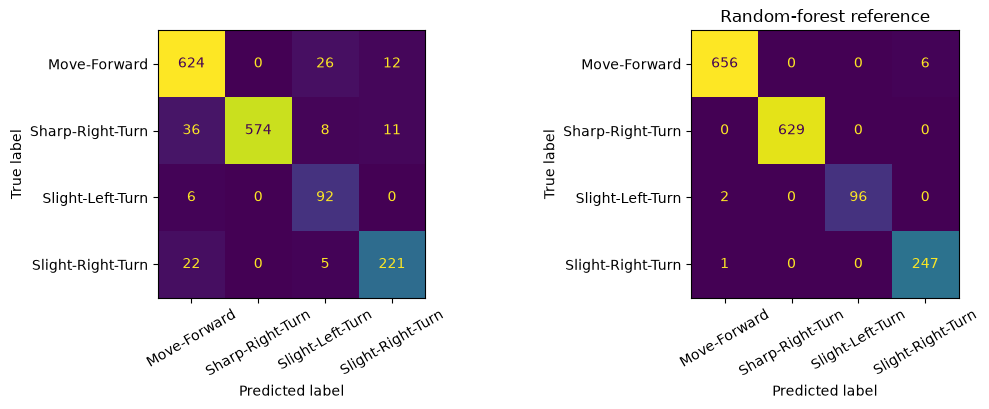

In [11]:
y_test = y[test_idx] 
predictions = {"Interpretable rule tree": rule_model.predict(X.loc[test_idx, selected]), 
               "Random-forest reference": reference.predict(X.loc[test_idx])} 

rows = [] 
for name, prediction in predictions.items(): 
    precision, recall, f1, _ = precision_recall_fscore_support(y_test, prediction, average="macro") 
    rows.append({"model": name, "accuracy": accuracy_score(y_test, prediction), 
                 "macro_precision": precision, "macro_recall": recall, "macro_f1": f1}) 
metrics = pd.DataFrame(rows) 
metrics.to_csv(RESULTS / "metrics.csv", index=False) 
display(metrics.round(3)) 
    
labels = sorted(y.unique()) 
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2)) 
for ax, (name, prediction) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, prediction, labels=labels), display_labels=labels).plot (ax=ax, colorbar=False, xticks_rotation=30) 
ax.set_title(name) 
plt.tight_layout() 
plt.savefig(RESULTS / "confusion_matrices.png", dpi=160) 

precision, recall, f1, _ = precision_recall_fscore_support(y_test, predictions["Interpretable rule tree"], 
    labels=labels) 
per_class = pd.DataFrame({"precision": precision, "recall": recall, "f1": f1}, index=labels) 
per_class.to_csv(RESULTS / "rule_per_class.csv") 
display(per_class.round(3))
print("Hardest action for the rule controller (lowest recall):", per_class.recall.idxmin())

,noise_fraction_of_train_sd,macro_f1
0,0.00,0.895
1,0.02,0.858
2,0.05,0.787
3,0.10,0.706


Saved: ['confusion_matrices.png', 'feature_scores.csv', 'metrics.csv', 'noise_robustness.csv', 'noise_robustness.png', 'rule_controller.txt', 'rule_per_class.csv', 'split.csv']


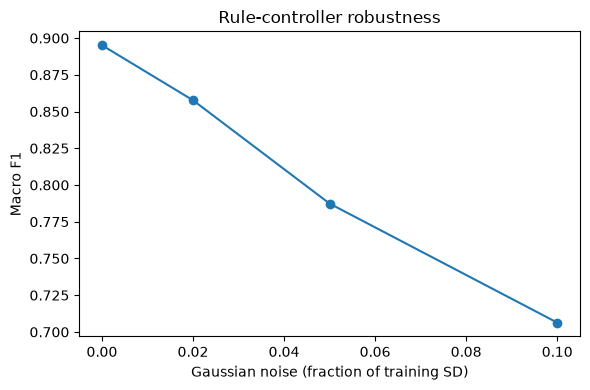

In [12]:
rng = np.random.default_rng(42) 
train_sd = X.loc[train_idx, selected].std().to_numpy() 
clean = X.loc[test_idx, selected].to_numpy(float) 

noise_rows = [] 
for fraction in [0.0, 0.02, 0.05, 0.10]:
    noisy = clean + rng.normal(0.0, fraction * train_sd, size=clean.shape) 
    prediction = rule_model.predict(pd.DataFrame(noisy, columns=selected)) 
    noise_rows.append({"noise_fraction_of_train_sd": fraction, "macro_f1": f1_score(y_test, prediction, 
     average="macro")}) 
noise = pd.DataFrame(noise_rows)
noise.to_csv(RESULTS / "noise_robustness.csv", index=False) 
display(noise.round(3)) 

ax = noise.plot(x="noise_fraction_of_train_sd", y="macro_f1", marker="o", legend=False, figsize=(6, 4)) 
ax.set(xlabel="Gaussian noise (fraction of training SD)", ylabel="Macro F1", title="Rule-controller robustness") 
plt.tight_layout() 
plt.savefig(RESULTS / "noise_robustness.png", dpi=160) 
print("Saved:", sorted(p.name for p in RESULTS.iterdir()))